**Practical 11 - Monte Carlo and MCMC**

**Aim**:

To analyse monthly sunspot data using Monte Carlo and Markov Chain Monte Carlo (MCMC) techniques, model the distribution of sunspot numbers using a Gamma distribution, estimate its parameters, and visualise the sampling process.

**Objectives**:
- To load and analyse monthly mean sunspot number data.
- To visualise sunspot activity over time.
- To model sunspot counts using a Gamma probability distribution.
- To understand the working of Monte Carlo simulation.
- To implement the Metropolis-Hastings MCMC algorithm.
- To estimate the Gamma distribution parameters \(a\) (shape) and \(b\) (scale).
- To visualise parameter traces and histograms.
- To remove burn-in samples and make parameter predictions.

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import gamma
from scipy.special import gammaln

# Load the sunspot dataset
url = "https://www.sidc.be/SILSO/DATA/SN_m_tot_V2.0.csv"

columns = [
    "Year", "Month", "Date", "Sunspot",
    "Standard_Deviation", "Observations", "Indicator"
]

df = pd.read_csv(url, sep=";", header=None, names=columns)

# Select data from January 1749 to November 2018
df = df[
    (df["Year"] >= 1749) &
    ((df["Year"] < 2018) |
     ((df["Year"] == 2018) & (df["Month"] <= 11)))
].copy()

# Remove missing values
df = df[df["Sunspot"] >= 0].copy()

# Create date column
df["Date"] = pd.to_datetime(
    dict(year=df["Year"], month=df["Month"], day=1)
)

# Display first five rows
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nTotal observations:", len(df))

   Year  Month       Date  Sunspot  Standard_Deviation  Observations  \
0  1749      1 1749-01-01     96.7                -1.0            -1   
1  1749      2 1749-02-01    104.3                -1.0            -1   
2  1749      3 1749-03-01    116.7                -1.0            -1   
3  1749      4 1749-04-01     92.8                -1.0            -1   
4  1749      5 1749-05-01    141.7                -1.0            -1   

   Indicator  
0          1  
1          1  
2          1  
3          1  
4          1  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 3239 entries, 0 to 3238
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Year                3239 non-null   int64         
 1   Month               3239 non-null   int64         
 2   Date                3239 non-null   datetime64[ns]
 3   Sunspot             3239 non-null   float64       
 4   Standard_Devi

**Explanation**:
- NumPy is used for numerical calculations.
- Pandas is used to load and process the dataset.
- Matplotlib and Seaborn are used for graphs.
- SciPy provides Gamma distribution functions.
- We select the required historical period and remove missing observations.

**Step 1: Plot sunspot data over the years**

In this step, we visualise monthly sunspot activity to understand its distribution and changing patterns.

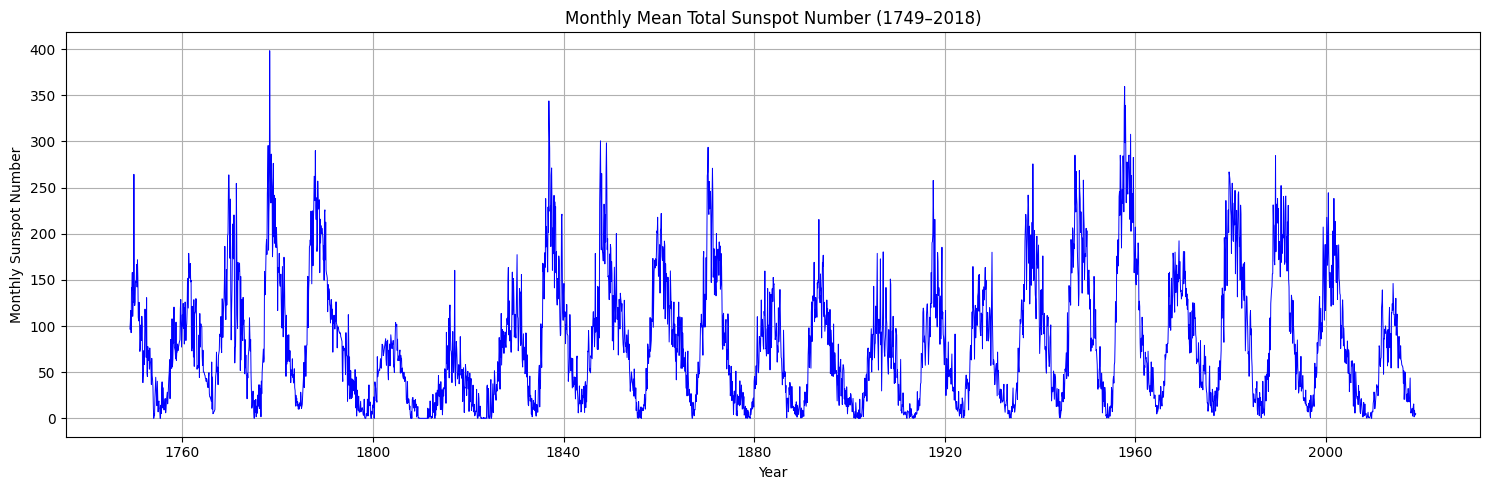

In [2]:
plt.figure(figsize=(15, 5))

plt.plot(
    df["Date"],
    df["Sunspot"],
    color="blue",
    linewidth=0.7
)

plt.title("Monthly Mean Total Sunspot Number (1749–2018)")
plt.xlabel("Year")
plt.ylabel("Monthly Sunspot Number")

plt.grid(True)
plt.tight_layout()
plt.show()

**Explanation**:

The graph displays changes in sunspot activity over time. We can observe repeated increases and decreases in sunspot numbers, representing solar activity cycles.

**Step 3: Model the phenomenon using a Gamma distribution**

A Gamma distribution is used to model positive sunspot counts.

We divide the timeline into 12-year cycles.

In [4]:
# Create 12-year solar cycle groups
df["Cycle"] = (df["Year"] - 1749) // 12

print("Number of 12-year cycles:", df["Cycle"].nunique())

# Extract positive sunspot observations
sunspots = df.loc[df["Sunspot"] > 0, "Sunspot"].values

# Fit Gamma distribution
a_fit, loc_fit, b_fit = gamma.fit(sunspots, floc=0)

print("Gamma Distribution Parameters:")
print("Shape parameter (a):", a_fit)
print("Scale parameter (b):", b_fit)



Number of 12-year cycles: 23
Gamma Distribution Parameters:
Shape parameter (a): 1.1742848202497331
Scale parameter (b): 71.64020804539345


**Explanation**:
- We group the observations into 12-year cycles.
- We use positive sunspot counts because the Gamma distribution is defined for positive values.
- gamma.fit() estimates the shape and scale parameters.


**Step 3: Histogram of sunspot counts**


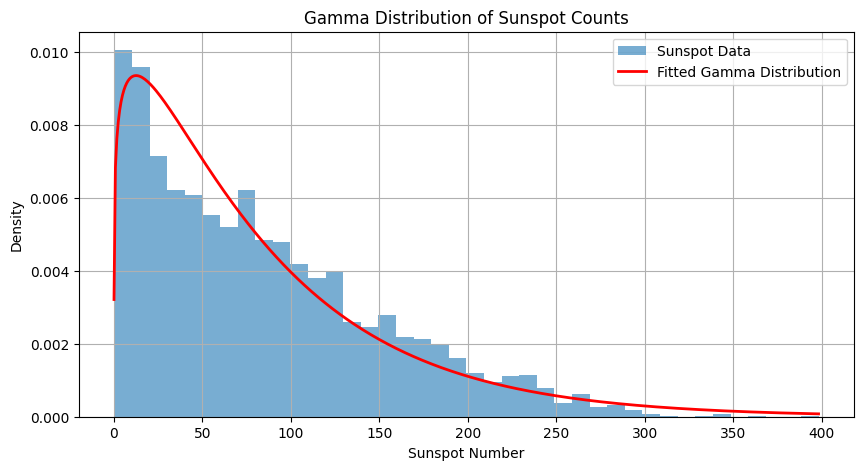

In [5]:
# Plot histogram and fitted Gamma distribution
plt.figure(figsize=(10, 5))

plt.hist(
    sunspots,
    bins=40,
    density=True,
    alpha=0.6,
    label="Sunspot Data"
)

x = np.linspace(0.01, sunspots.max(), 500)

plt.plot(
    x,
    gamma.pdf(x, a_fit, scale=b_fit),
    color="red",
    linewidth=2,
    label="Fitted Gamma Distribution"
)

plt.title("Gamma Distribution of Sunspot Counts")
plt.xlabel("Sunspot Number")
plt.ylabel("Density")

plt.legend()
plt.grid(True)
plt.show()

- The histogram shows the actual distribution.
- The red curve represents the fitted Gamma distribution.

**Step 4: Monte Carlo simulation using a = 4 and b = 10**

In this step, we use the initial parameters:

Shape parameter

a=4

Scale parameter

b=10

We generate random samples using the Gamma distribution and visualise three groups:

First 50 samples.

All samples.

Last 50 samples.

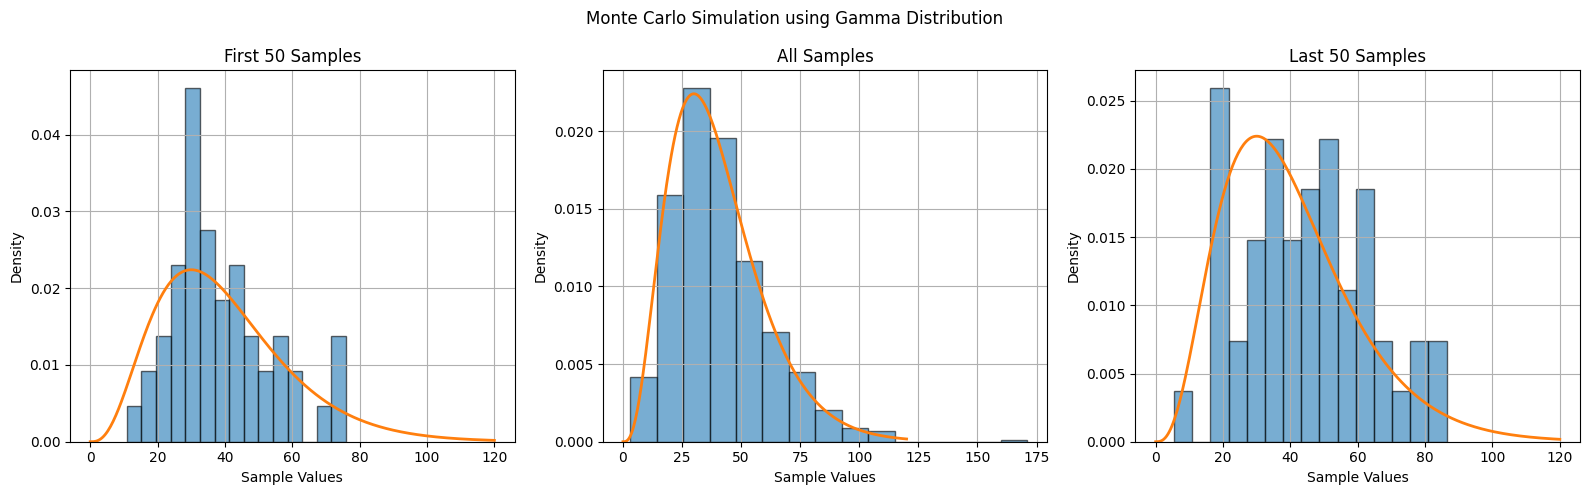

In [6]:
# Initial Gamma distribution parameters
a = 4
b = 10

# Generate 1000 random samples
np.random.seed(42)

samples = np.random.gamma(
    shape=a,
    scale=b,
    size=1000
)

# First 50 samples
first_50 = samples[:50]

# All samples
all_samples = samples

# Last 50 samples
last_50 = samples[-50:]

# Plot all three groups
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

groups = [
    (first_50, "First 50 Samples"),
    (all_samples, "All Samples"),
    (last_50, "Last 50 Samples")
]

for ax, (data, title) in zip(axes, groups):

    ax.hist(
        data,
        bins=15,
        density=True,
        alpha=0.6,
        edgecolor="black"
    )

    x = np.linspace(0, 120, 300)

    ax.plot(
        x,
        gamma.pdf(x, a, scale=b),
        linewidth=2
    )

    ax.set_title(title)
    ax.set_xlabel("Sample Values")
    ax.set_ylabel("Density")
    ax.grid(True)

plt.suptitle("Monte Carlo Simulation using Gamma Distribution")
plt.tight_layout()
plt.show()

**Explanation**:

Monte Carlo simulation generates random values from a probability distribution.

Here, we generate 1000 samples from a Gamma distribution using a=4 and b=10.

The three histograms help us compare the first 50 samples, the complete sample set and the last 50 samples with the theoretical Gamma distribution.

**Implement MCMC using the Metropolis-Hastings algorithm**

In this step, we estimate the unknown Gamma parameters using MCMC.

We start with:

Initial
a=4

Initial
b=10

Number of iterations = 10,000

Burn-in samples = 2,000

The algorithm generates new values of
a and b, then accepts or rejects them based on their posterior probability.

In [10]:
def log_posterior(a, b, data):

    if a <= 0 or b <= 0:
        return -np.inf

    log_likelihood = np.sum(
        gamma.logpdf(data, a=a, scale=b)
    )

    # Weak exponential priors
    log_prior = -0.01 * a - 0.001 * b

    return log_likelihood + log_prior


np.random.seed(42)

n_iterations = 10000

chain = np.zeros((n_iterations, 2))

current_a = 4.0
current_b = 10.0

# Include Jacobian terms for log-space sampling
current_log_prob = (
    log_posterior(current_a, current_b, sunspots)
    + np.log(current_a)
    + np.log(current_b)
)

accepted = 0

for i in range(n_iterations):

    # Propose new values in log space
    proposed_a = np.exp(
        np.log(current_a) + np.random.normal(0, 0.08)
    )

    proposed_b = np.exp(
        np.log(current_b) + np.random.normal(0, 0.08)
    )

    proposed_log_prob = (
        log_posterior(proposed_a, proposed_b, sunspots)
        + np.log(proposed_a)
        + np.log(proposed_b)
    )

    log_acceptance = proposed_log_prob - current_log_prob

    if np.log(np.random.rand()) < min(0, log_acceptance):

        current_a = proposed_a
        current_b = proposed_b

        current_log_prob = proposed_log_prob

        accepted += 1

    chain[i] = [current_a, current_b]


print("MCMC completed successfully!")
print("Acceptance Rate:", accepted / n_iterations)

MCMC completed successfully!
Acceptance Rate: 0.0955


**Explanation**:

The Metropolis-Hastings algorithm works as follows:
1. Start with initial values of \(a\) and \(b\).
2. Generate new proposed values.
3. Calculate their posterior probability.
4. Accept the proposed values if they satisfy the acceptance rule.
5. Otherwise, retain the previous values.
6. Repeat the process for 10,000 iterations.
This generates a chain of possible parameter values.

**Step 5: Visualise traces of a and b and their histograms**

A trace plot shows how the estimated parameters change during MCMC iterations.

We remove the first 2,000 samples because they are considered burn-in samples. These initial samples may not represent the final stationary distribution.

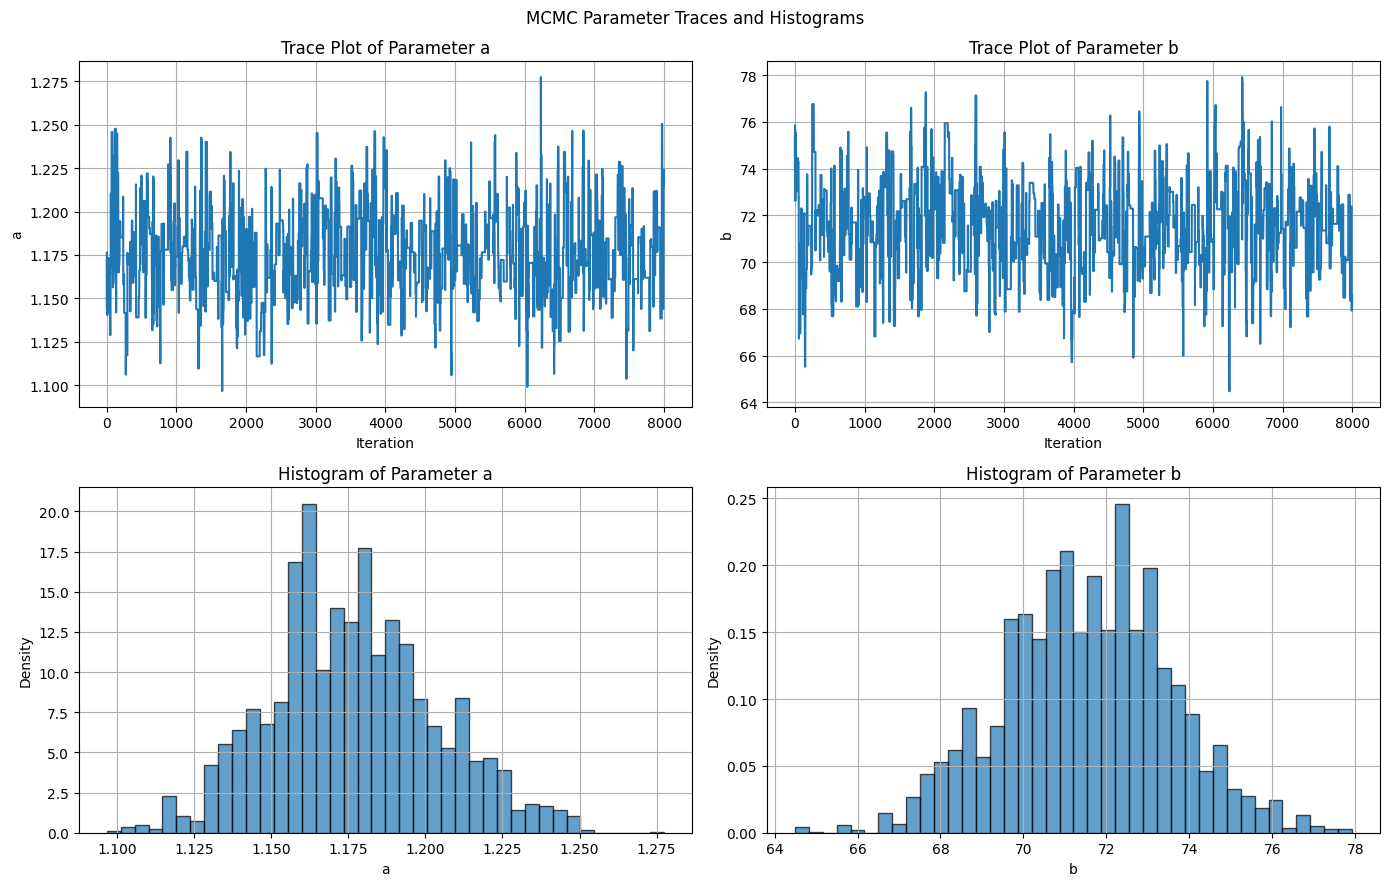

In [8]:
# Remove burn-in samples
burn_in = 2000

a_samples = chain[burn_in:, 0]
b_samples = chain[burn_in:, 1]

# Create trace plots and histograms
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Trace plot of a
axes[0, 0].plot(a_samples)
axes[0, 0].set_title("Trace Plot of Parameter a")
axes[0, 0].set_xlabel("Iteration")
axes[0, 0].set_ylabel("a")
axes[0, 0].grid(True)

# Trace plot of b
axes[0, 1].plot(b_samples)
axes[0, 1].set_title("Trace Plot of Parameter b")
axes[0, 1].set_xlabel("Iteration")
axes[0, 1].set_ylabel("b")
axes[0, 1].grid(True)

# Histogram of a
axes[1, 0].hist(
    a_samples,
    bins=40,
    density=True,
    alpha=0.7,
    edgecolor="black"
)

axes[1, 0].set_title("Histogram of Parameter a")
axes[1, 0].set_xlabel("a")
axes[1, 0].set_ylabel("Density")
axes[1, 0].grid(True)

# Histogram of b
axes[1, 1].hist(
    b_samples,
    bins=40,
    density=True,
    alpha=0.7,
    edgecolor="black"
)

axes[1, 1].set_title("Histogram of Parameter b")
axes[1, 1].set_xlabel("b")
axes[1, 1].set_ylabel("Density")
axes[1, 1].grid(True)

plt.suptitle("MCMC Parameter Traces and Histograms")
plt.tight_layout()
plt.show()

**Explanation**:
- Trace plots show the movement of parameters during sampling.
- Histograms show the distribution of sampled parameter values.
- Burn-in samples are removed to reduce the effect of initial values.
- The remaining samples are used for parameter estimation.

**Step 6: Prediction time of a and b**

In this step, we calculate the final estimated values of the shape parameter and scale parameter using the MCMC samples after removing burn-in.

We also calculate the 95% credible intervals.

In [9]:
# Calculate estimated parameters
predicted_a = np.mean(a_samples)
predicted_b = np.mean(b_samples)

# Calculate median values
median_a = np.median(a_samples)
median_b = np.median(b_samples)

# Calculate 95% credible intervals
a_interval = np.percentile(a_samples, [2.5, 97.5])
b_interval = np.percentile(b_samples, [2.5, 97.5])

print("Final Parameter Predictions")
print("--------------------------------")

print("Estimated Shape Parameter (a):", predicted_a)
print("Estimated Scale Parameter (b):", predicted_b)

print("\nMedian of a:", median_a)
print("Median of b:", median_b)

print("\n95% Credible Interval for a:", a_interval)
print("95% Credible Interval for b:", b_interval)

Final Parameter Predictions
--------------------------------
Estimated Shape Parameter (a): 1.1764951285263783
Estimated Scale Parameter (b): 71.52820760032704

Median of a: 1.1759269664486065
Median of b: 71.57044548632389

95% Credible Interval for a: [1.12916696 1.23426638]
95% Credible Interval for b: [67.68982662 75.54147343]


**Explanation**:
- The mean of the MCMC samples provides an estimate of each parameter.
- The median gives another measure of the central value.
- The 95% credible interval represents the range containing 95% of the posterior probability.
- These estimated values help us understand the Gamma distribution that best describes the positive sunspot observations under our model.

**Conclusion**:

In this practical, we studied monthly sunspot activity using Monte Carlo and Markov Chain Monte Carlo techniques.

We plotted the historical sunspot data and modelled its positive values using a Gamma distribution. Monte Carlo simulation was performed using the initial parameters \(a=4\) and \(b=10\).

The Metropolis-Hastings algorithm was then implemented to estimate the Gamma distribution parameters. Burn-in samples were removed, and trace plots and histograms were generated to understand the sampling behaviour.

Finally, the estimated values of the shape and scale parameters were calculated using the remaining MCMC samples.

Thus, we successfully implemented Monte Carlo and MCMC techniques for analysing sunspot data and estimating probability distribution parameters.